# Figure 5: 3D obstacle course

Reproduces Fig. 5(a) and 5(c): the four lowest-pressure paths through the 3D hardware obstacle course, and their predicted growth pressure versus deployed length.

The course is a grid of 6 in voxels, 3 wide, 3 deep and 4 tall, with three horizontal floors. Each floor is a 3 x 3 grid with two open cells. As in Figure 1, we solve each combination of openings (a *route*) separately and rank them by pressure.

In 3D, paths can bend anywhere along an obstacle edge, so we add evenly spaced points along each edge. `EDGE_SAMPLES = 4` places two points between the corners of each edge, as in the paper.

Runtime: under a minute.

In [1]:
import sys; sys.path.insert(0, "..")   # use the repo's vine_planner without pip install

import itertools
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from vine_planner.obstacle_course import ObstacleCourseVoxels
from vine_planner.path_planner import PathPlanner
from vine_planner.utils import pressure_profile, pressure_conversion

PSI_TO_KPA = pressure_conversion("psi", "kpa")
IN_TO_M = 0.0254

## Course

`OPEN[level]` lists the open `(row, column)` cells on each floor. The start is at the bottom of the course in one corner; the end is at the top in the opposite corner.

In [2]:
VOXEL, UNITS = 6.0, "in"
EDGE_SAMPLES = 4                    # points per edge, corners included
WIDTH, HEIGHT, DEPTH = 3 * VOXEL, 4 * VOXEL, 3 * VOXEL
BURST_KPA = 21.5                    # hypothetical burst pressure (dashed line)

OPEN = {
    1: [(1, 1), (3, 1)],
    2: [(1, 3), (3, 3)],
    3: [(1, 1), (1, 3)],
}

START = np.array([WIDTH, 0.0, 0.0])
END = np.array([0.0, HEIGHT, DEPTH])


def closed_cells(open_cells):
    """(level, row, column) of every walled cell."""
    return [
        (level, row, column)
        for level, cells in open_cells.items()
        for row in (1, 2, 3)
        for column in (1, 2, 3)
        if (row, column) not in cells
    ]


def walls(open_cells):
    """One wall (voxel i, j, k, face) per closed cell; face 3 is -y."""
    return [(column - 1, level, row - 1, 3) for level, row, column in closed_cells(open_cells)]

## Solve every route

In [3]:
results = []
for route in itertools.product(*OPEN.values()):
    course = ObstacleCourseVoxels(
        width=WIDTH, height=HEIGHT, depth=DEPTH, voxel_size=VOXEL,
        spacing=VOXEL / (EDGE_SAMPLES - 1),
        obstacles=walls({level: [cell] for level, cell in zip(OPEN, route)}),
    )
    planner = PathPlanner(course, start=START, end=END, length_units=UNITS)
    path = planner.compute_pressure_path()
    results.append((planner.total_pressure * PSI_TO_KPA, route, path))

results.sort(key=lambda r: r[0])
PARAMS = planner.model_parameters

for rank, (pressure, route, _) in enumerate(results, start=1):
    print(f"{rank}. {pressure:6.2f} kPa   route {route}")

1.  21.24 kPa   route ((1, 1), (1, 3), (1, 3))
2.  25.12 kPa   route ((1, 1), (1, 3), (1, 1))
3.  26.03 kPa   route ((3, 1), (1, 3), (1, 3))
4.  31.39 kPa   route ((3, 1), (3, 3), (1, 3))
5.  31.53 kPa   route ((3, 1), (1, 3), (1, 1))
6.  36.31 kPa   route ((1, 1), (3, 3), (1, 3))
7.  36.48 kPa   route ((3, 1), (3, 3), (1, 1))
8.  37.42 kPa   route ((1, 1), (3, 3), (1, 1))


## The four paths in the paper

In [4]:
PAPER_ROUTES = [
    ((1, 1), (1, 3), (1, 3)),
    ((3, 1), (1, 3), (1, 3)),
    ((3, 1), (3, 3), (1, 3)),
    ((1, 1), (3, 3), (1, 3)),
]
COLORS = ["tab:green", "tab:blue", "tab:orange", "tab:red"]
LABELS = ["Best", "2nd", "3rd", "4th"]

by_route = {route: (pressure, route, path) for pressure, route, path in results}
shown = [by_route[route] for route in PAPER_ROUTES]

### Fig. 5(a): paths in 3D

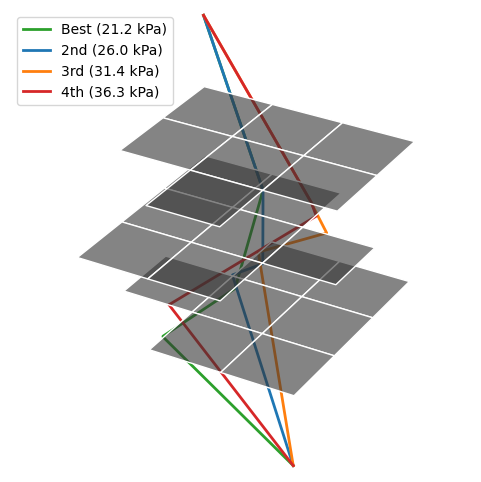

In [5]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")

# Plot (x, z, y) so that the course's vertical axis (y) points up.
quads = [
    [((c - 1) * VOXEL, (r - 1) * VOXEL, level * VOXEL), (c * VOXEL, (r - 1) * VOXEL, level * VOXEL),
     (c * VOXEL, r * VOXEL, level * VOXEL), ((c - 1) * VOXEL, r * VOXEL, level * VOXEL)]
    for level, r, c in closed_cells(OPEN)
]
ax.add_collection3d(Poly3DCollection(quads, facecolor="0.2", edgecolor="white", alpha=0.6))

for (pressure, route, path), color, label in zip(shown, COLORS, LABELS):
    ax.plot(path[:, 0], path[:, 2], path[:, 1], color=color, lw=2, label=f"{label} ({pressure:.1f} kPa)")

ax.set_xlim(0, WIDTH); ax.set_ylim(0, DEPTH); ax.set_zlim(0, HEIGHT)
ax.set_box_aspect((WIDTH, DEPTH, HEIGHT))
ax.set_axis_off()
ax.legend(loc="upper left")
plt.show()

### Fig. 5(c): pressure vs. deployed length

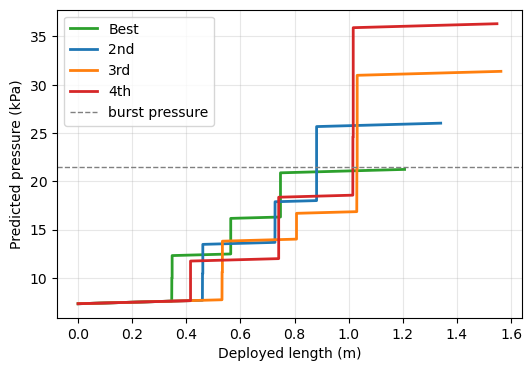

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
for (pressure, route, path), color, label in zip(shown, COLORS, LABELS):
    s, p = pressure_profile(path, length_units=UNITS, **PARAMS)
    ax.plot(s * IN_TO_M, p * PSI_TO_KPA, color=color, lw=2, label=label)
ax.axhline(BURST_KPA, color="gray", ls="--", lw=1, label="burst pressure")
ax.set_xlabel("Deployed length (m)")
ax.set_ylabel("Predicted pressure (kPa)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()